# Module 5: Neural Network / MLP Experiments

## 5.1 · MLP configuration

In [ ]:
PROJECT_DIR = "CounterShield"
DATASETS = ["bot_iot", "cic_ids2017", "unsw_nb15"]
SEEDS = [42, 7, 2026]
MAX_EPOCHS, PATIENCE = 40, 6
CLASS_WEIGHTING = "balanced"
SELECTION_METRIC = "f1_macro"
CPU_TRAIN_CAP = 300_000
FORCE_RETRAIN = False

EXPERIMENTS = {
    "mlp_128_64":     {"hidden": [128, 64],      "dropout": 0.1, "batchnorm": False, "lr": 1e-3, "weight_decay": 1e-5, "batch_size": 2048},
    "mlp_256_128_64": {"hidden": [256, 128, 64], "dropout": 0.2, "batchnorm": True,  "lr": 1e-3, "weight_decay": 1e-5, "batch_size": 2048},
    "mlp_512_256":    {"hidden": [512, 256],     "dropout": 0.3, "batchnorm": True,  "lr": 5e-4, "weight_decay": 1e-4, "batch_size": 4096},
}

## 5.2 · GPU setup

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
import sys, warnings, platform, datetime as dt
try:
    from IPython.display import display
except ImportError:
    display = print

import os, gc, json, time, copy, random, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import torch, torch.nn as nn
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, roc_auc_score, average_precision_score, confusion_matrix)

def sha256_file(path, block=8 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(block), b""):
            h.update(chunk)
    return h.hexdigest()

def _strat(y):
    y = pd.Series(y).astype(str); vc = y.value_counts()
    return y.where(~y.isin(vc.index[vc < 4]), "__rare__").to_numpy()

def load_split(base, m3, key, split, cap=None, seed=42):
    info = m3["datasets"][key]; feats = info["feature_names"]
    d = pd.read_parquet(base / info["files"][split]["path"], columns=feats + ["y_binary", "y_class", "row"])
    if cap and len(d) > cap:
        keep, _ = train_test_split(np.arange(len(d)), train_size=cap, stratify=_strat(d["y_class"]), random_state=seed)
        d = d.iloc[np.sort(keep)].reset_index(drop=True)
    return (d[feats].to_numpy(dtype=np.float32), d["y_binary"].to_numpy().astype(int),
            d["y_class"].astype(str).to_numpy(), d["row"].to_numpy())

def binary_metrics(y, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    return {"threshold": thr, "accuracy": accuracy_score(y, pred), "balanced_accuracy": balanced_accuracy_score(y, pred),
            "precision_attack": precision_score(y, pred, zero_division=0), "recall_attack": recall_score(y, pred, zero_division=0),
            "f1_attack": f1_score(y, pred, zero_division=0), "f1_macro": f1_score(y, pred, average="macro", zero_division=0),
            "mcc": matthews_corrcoef(y, pred), "roc_auc": roc_auc_score(y, prob) if both else np.nan,
            "pr_auc": average_precision_score(y, prob) if both else np.nan,
            "fpr": fp / max(fp + tn, 1), "fnr": fn / max(fn + tp, 1), "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

def tune_threshold(y, prob, metric="f1_macro"):
    grid = np.unique(np.concatenate([np.linspace(0.01, 0.99, 99), np.quantile(prob, np.linspace(0.01, 0.99, 99))]))
    scores = [(t, binary_metrics(y, prob, t)[metric]) for t in grid]
    best = max(scores, key=lambda s: (s[1], -abs(s[0] - 0.5)))
    return float(best[0]), float(best[1])

def per_class_detection(y_class, y, prob, thr):
    pred = (prob >= thr).astype(int)
    g = pd.DataFrame({"y_class": y_class, "y": y, "pred": pred}).groupby("y_class") \
          .agg(rows=("y", "size"), is_attack=("y", "max"), flagged=("pred", "mean")).reset_index()
    g["detection_rate"] = np.where(g.is_attack == 1, g.flagged, np.nan)
    g["false_alarm_rate"] = np.where(g.is_attack == 0, g.flagged, np.nan)
    return g.drop(columns="flagged")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

class MLP(nn.Module):
    def __init__(self, n_in, hidden, dropout=0.1, batchnorm=False):
        super().__init__()
        layers, d = [], n_in
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if batchnorm: layers.append(nn.BatchNorm1d(h))
            layers += [nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(-1)

def n_params(model):
    return int(sum(p.numel() for p in model.parameters()))

@torch.no_grad()
def predict_logits(model, X, device, batch=65536):
    model.eval()
    out = []
    for i in range(0, len(X), batch):
        xb = X[i:i + batch]
        xb = xb if isinstance(xb, torch.Tensor) else torch.from_numpy(xb)
        out.append(model(xb.to(device, non_blocking=True)).float().cpu())
    return torch.cat(out)

def predict_proba(model, X, device):
    return torch.sigmoid(predict_logits(model, X, device)).numpy().astype(np.float32)

def train_mlp(exp, Xtr, ytr, Xva, yva, device, seed, max_epochs, patience, class_weighting="balanced",
              fixed_epochs=None, log=print):
    set_seed(seed)
    model = MLP(Xtr.shape[1], exp["hidden"], exp["dropout"], exp["batchnorm"]).to(device)
    pos = float(ytr.mean())
    pos_weight = torch.tensor([(1 - pos) / pos if class_weighting == "balanced" else 1.0], device=device)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    opt = torch.optim.AdamW(model.parameters(), lr=exp["lr"], weight_decay=exp["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2) if fixed_epochs is None else None
    Xt = torch.from_numpy(Xtr).to(device); yt = torch.from_numpy(ytr.astype(np.float32)).to(device)
    Xv = torch.from_numpy(Xva).to(device) if Xva is not None else None
    yv_t = torch.from_numpy(yva.astype(np.float32)).to(device) if yva is not None else None
    g = torch.Generator(device="cpu").manual_seed(seed)
    n, bs = len(Xt), exp["batch_size"]
    hist, best, best_state, best_epoch, bad = [], -1.0, None, 0, 0
    epochs = fixed_epochs or max_epochs
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); tot = 0.0
        perm = torch.randperm(n, generator=g).to(device)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            if len(idx) < 2: continue
            opt.zero_grad(set_to_none=True)
            loss = loss_fn(model(Xt[idx]), yt[idx]); loss.backward(); opt.step()
            tot += loss.item() * len(idx)
        row = {"epoch": ep, "train_loss": tot / n, "lr": opt.param_groups[0]["lr"]}
        if Xv is not None:
            logits = predict_logits(model, Xv, device)
            row["val_loss"] = float(loss_fn(logits.to(device), yv_t).item())
            p = torch.sigmoid(logits).numpy()
            row["val_f1_macro"] = f1_score(yva, (p >= 0.5).astype(int), average="macro", zero_division=0)
            row["val_pr_auc"] = average_precision_score(yva, p)
        row["seconds"] = time.time() - t0
        hist.append(row)
        if Xv is not None:
            sched.step(row["val_f1_macro"])
            if row["val_f1_macro"] > best + 1e-5:
                best, best_epoch, bad = row["val_f1_macro"], ep, 0
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
            if ep == 1 or ep % 5 == 0 or bad == 0:
                log(f"      epoch {ep:>2}  train {row['train_loss']:.4f}  val {row['val_loss']:.4f}  "
                    f"F1 {row['val_f1_macro']:.4f}  PR-AUC {row['val_pr_auc']:.4f}  {row['seconds']:.1f}s{'  *' if bad == 0 else ''}")
            if bad >= patience:
                log(f"      early stop at epoch {ep} (best epoch {best_epoch})"); break
    if best_state is None:
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}; best_epoch = len(hist)
    model.load_state_dict(best_state)
    del Xt, yt, Xv; torch.cuda.empty_cache() if device.type == "cuda" else None
    return model, pd.DataFrame(hist), best_epoch, float(pos_weight.item())

def save_ckpt(path, model, exp, hist, best_epoch, pos_weight, seed, n_train, n_features, extra=None):
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save({"state_dict": model.state_dict(), "exp": exp, "history": hist.to_dict("list"), "best_epoch": best_epoch,
                "pos_weight": pos_weight, "seed": seed, "n_train": n_train, "n_features": n_features,
                "torch": torch.__version__, **(extra or {})}, path)

def load_ckpt(path, device):
    ck = torch.load(path, map_location=device, weights_only=False)
    m = MLP(ck["n_features"], ck["exp"]["hidden"], ck["exp"]["dropout"], ck["exp"]["batchnorm"]).to(device)
    m.load_state_dict(ck["state_dict"])
    return m, pd.DataFrame(ck["history"]), ck

def mcnemar(y, pred_a, pred_b):
    a_ok, b_ok = pred_a == y, pred_b == y
    b = int((a_ok & ~b_ok).sum()); c = int((~a_ok & b_ok).sum())
    if b + c == 0:
        return b, c, 1.0
    if b + c < 25:
        p = stats.binomtest(b, b + c, 0.5).pvalue
    else:
        p = stats.chi2.sf((abs(b - c) - 1) ** 2 / (b + c), 1)
    return b, c, float(p)

def _macro_f1_counts(y, p):
    tp = (y & p).sum(-1); fp = (~y & p).sum(-1); fn = (y & ~p).sum(-1); tn = (~y & ~p).sum(-1)
    f1a = 2 * tp / np.maximum(2 * tp + fp + fn, 1); f1b = 2 * tn / np.maximum(2 * tn + fn + fp, 1)
    return (f1a + f1b) / 2

def bootstrap_f1_diff(y, pred_a, pred_b, n_boot=500, seed=42, chunk=20):
    rng = np.random.default_rng(seed)
    y, pa, pb = y.astype(bool), pred_a.astype(bool), pred_b.astype(bool)
    n, diffs = len(y), []
    for s in range(0, n_boot, chunk):
        idx = rng.integers(0, n, size=(min(chunk, n_boot - s), n))
        diffs.append(_macro_f1_counts(y[idx], pb[idx]) - _macro_f1_counts(y[idx], pa[idx]))
    d = np.concatenate(diffs)
    point = float(_macro_f1_counts(y[None], pb[None])[0] - _macro_f1_counts(y[None], pa[None])[0])
    return point, float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))

BASE      = Path("/content/drive/MyDrive") / PROJECT_DIR
M3        = json.loads((BASE / "results" / "module3" / "module3_manifest.json").read_text())
M4_RES    = BASE / "results" / "module4"
MODEL_DIR = BASE / "models" / "module5"
RES       = BASE / "results" / "module5"
for p in (MODEL_DIR / "dev", MODEL_DIR / "final", RES / "histories", RES / "val_probs", RES / "test_predictions", RES / "figures"):
    p.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    GPU = {"name": props.name, "memory_GB": round(props.total_memory / 2**30, 1), "cuda": torch.version.cuda}
    print(f"GPU: {GPU['name']} ({GPU['memory_GB']} GB), CUDA {GPU['cuda']}, torch {torch.__version__}")
else:
    GPU = None
    warnings.warn(f"No GPU found - training on CPU with train capped at {CPU_TRAIN_CAP:,} rows. Use Runtime -> Change runtime type -> T4 GPU.")
TRAIN_CAP = None if GPU else CPU_TRAIN_CAP
(RES / "mlp_config.json").write_text(json.dumps({
    "datasets": DATASETS, "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE, "class_weighting": CLASS_WEIGHTING,
    "selection_metric": SELECTION_METRIC, "train_cap": TRAIN_CAP, "experiments": EXPERIMENTS, "device": GPU or "cpu",
    "torch": torch.__version__, "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")}, indent=2))
DATA = {}
for k in DATASETS:
    DATA[k] = {"train": load_split(BASE, M3, k, "train", cap=TRAIN_CAP), "val": load_split(BASE, M3, k, "val")}
    Xtr, ytr = DATA[k]["train"][:2]
    print(f"{k:<12} train {Xtr.shape[0]:>9,} x {Xtr.shape[1]:<3} | val {len(DATA[k]['val'][1]):>8,} | attack rate {ytr.mean():.3f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4 (14.6 GB), CUDA 13.0, torch 2.14.1+cu130
bot_iot      train   632,744 x 46  | val  135,589 | attack rate 0.990
cic_ids2017  train 1,539,015 x 69  | val  329,790 | attack rate 0.153
unsw_nb15    train    84,377 x 81  | val   14,891 | attack rate 0.480


## 5.3 · Training

In [ ]:
RUNS = {}
for k in DATASETS:
    Xtr, ytr, _, _ = DATA[k]["train"]; Xva, yva, _, _ = DATA[k]["val"]
    for name, exp in EXPERIMENTS.items():
        for seed in SEEDS:
            path = MODEL_DIR / "dev" / f"{k}__{name}__s{seed}.pt"
            if path.exists() and not FORCE_RETRAIN:
                model, hist, ck = load_ckpt(path, DEVICE); best_epoch, secs = ck["best_epoch"], ck["train_seconds"]
                print(f"{k:<12} {name:<15} seed {seed:<5} loaded checkpoint (best epoch {best_epoch})")
            else:
                print(f"{k:<12} {name:<15} seed {seed:<5} training on {DEVICE.type}...")
                t0 = time.time()
                model, hist, best_epoch, pw = train_mlp(exp, Xtr, ytr, Xva, yva, DEVICE, seed, MAX_EPOCHS, PATIENCE, CLASS_WEIGHTING)
                secs = time.time() - t0
                save_ckpt(path, model, exp, hist, best_epoch, pw, seed, len(ytr), Xtr.shape[1], {"train_seconds": secs, "dataset": k})
                print(f"      done in {secs:.0f}s, best epoch {best_epoch}")
            hist.to_csv(RES / "histories" / f"{k}__{name}__s{seed}.csv", index=False)
            p = predict_proba(model, Xva, DEVICE); np.save(RES / "val_probs" / f"{k}__{name}__s{seed}.npy", p)
            RUNS[(k, name, seed)] = {"hist": hist, "best_epoch": best_epoch, "train_seconds": secs, "params": n_params(model), "val_prob": p}
            del model; gc.collect()

bot_iot      mlp_128_64      seed 42    loaded checkpoint (best epoch 3)
bot_iot      mlp_128_64      seed 7     loaded checkpoint (best epoch 4)
bot_iot      mlp_128_64      seed 2026  loaded checkpoint (best epoch 4)
bot_iot      mlp_256_128_64  seed 42    loaded checkpoint (best epoch 5)
bot_iot      mlp_256_128_64  seed 7     loaded checkpoint (best epoch 3)
bot_iot      mlp_256_128_64  seed 2026  loaded checkpoint (best epoch 5)
bot_iot      mlp_512_256     seed 42    loaded checkpoint (best epoch 3)
bot_iot      mlp_512_256     seed 7     loaded checkpoint (best epoch 3)
bot_iot      mlp_512_256     seed 2026  loaded checkpoint (best epoch 5)
cic_ids2017  mlp_128_64      seed 42    training on cuda...
      epoch  1  train 0.1144  val 0.0487  F1 0.9818  PR-AUC 0.9976  2.5s  *
      epoch  2  train 0.0472  val 0.0385  F1 0.9896  PR-AUC 0.9985  1.8s  *
      epoch  3  train 0.0388  val 0.0310  F1 0.9926  PR-AUC 0.9989  1.7s  *
      epoch  5  train 0.0309  val 0.0264  F1 0.9929  PR

## 5.4 · Validation

In [ ]:
rows = []
for (k, name, seed), r in RUNS.items():
    m = binary_metrics(DATA[k]["val"][1], r["val_prob"])
    m.update(dataset=k, experiment=name, seed=seed, best_epoch=r["best_epoch"], epochs_run=len(r["hist"]),
             train_seconds=round(r["train_seconds"], 1), params=r["params"])
    rows.append(m)
val_runs = pd.DataFrame(rows)
val_runs.to_csv(RES / "validation_runs.csv", index=False)
agg = val_runs.groupby(["dataset", "experiment"]).agg(
    f1_macro_mean=("f1_macro", "mean"), f1_macro_std=("f1_macro", "std"), pr_auc_mean=("pr_auc", "mean"),
    mcc_mean=("mcc", "mean"), fpr_mean=("fpr", "mean"), fnr_mean=("fnr", "mean"), best_epoch_mean=("best_epoch", "mean"),
    train_seconds_mean=("train_seconds", "mean"), params=("params", "first")).reset_index()
agg.to_csv(RES / "validation_summary.csv", index=False)
display(agg.style.format({c: "{:.4f}" for c in ["f1_macro_mean", "f1_macro_std", "pr_auc_mean", "mcc_mean", "fpr_mean", "fnr_mean"]}).hide(axis="index"))

dataset,experiment,f1_macro_mean,f1_macro_std,pr_auc_mean,mcc_mean,fpr_mean,fnr_mean,best_epoch_mean,train_seconds_mean,params
bot_iot,mlp_128_64,0.9688,0.0085,1.0000,0.9389,0.0117,0.0012,3.666667,8.266667,14337
bot_iot,mlp_256_128_64,0.9644,0.0044,1.0000,0.9308,0.0071,0.0015,4.333333,10.000000,54145
bot_iot,mlp_512_256,0.9588,0.0045,1.0000,0.9202,0.0078,0.0017,3.666667,4.900000,157185
cic_ids2017,mlp_128_64,0.9961,0.0001,0.9996,0.9922,0.0014,0.0054,26.666667,62.333333,17281
cic_ids2017,mlp_256_128_64,0.9959,0.0000,0.9996,0.9917,0.0016,0.0053,24.333333,81.966667,60033
cic_ids2017,mlp_512_256,0.9955,0.0002,0.9996,0.9910,0.0018,0.0052,26.666667,44.766667,168961
unsw_nb15,mlp_128_64,0.9157,0.0019,0.9734,0.8347,0.1221,0.0434,14.000000,2.266667,18817
unsw_nb15,mlp_256_128_64,0.9193,0.0016,0.9769,0.8397,0.1003,0.0594,25.000000,4.800000,63105
unsw_nb15,mlp_512_256,0.9177,0.0012,0.9750,0.8369,0.1068,0.0557,31.333333,2.933333,175105


## 5.5 · Training-history analysis

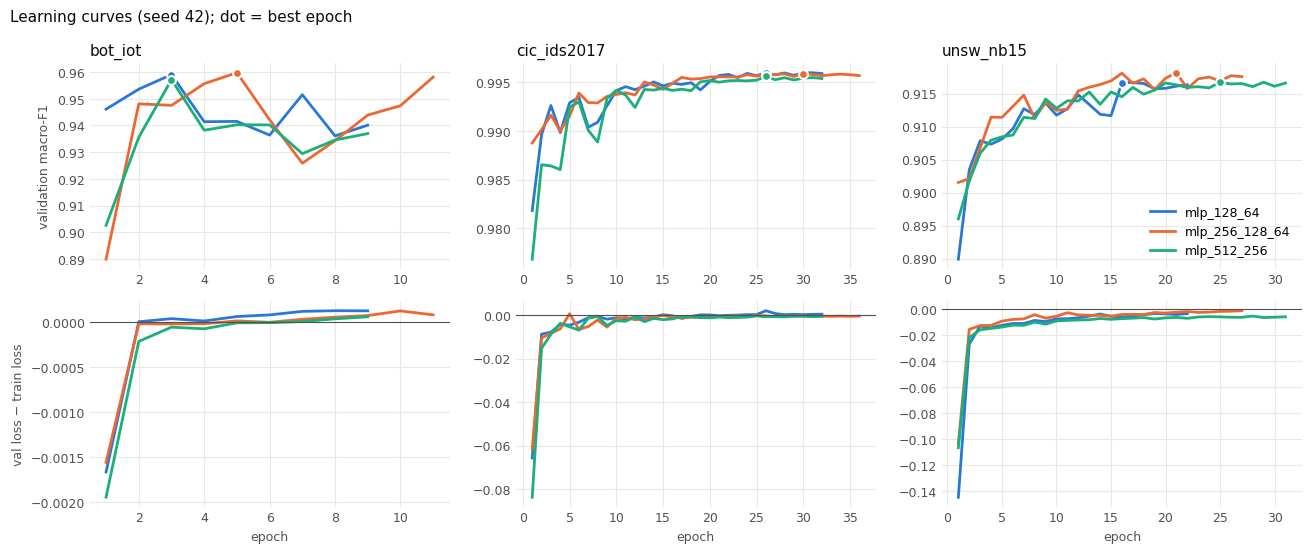

epochs_run  best_epoch  gap_at_best  gap_at_end  \
dataset     experiment                                                        
bot_iot     mlp_128_64          9.6667      3.6667       0.0001      0.0001   
            mlp_256_128_64     10.3333      4.3333       0.0000      0.0001   
            mlp_512_256         9.6667      3.6667      -0.0000      0.0001   
cic_ids2017 mlp_128_64         32.6667     26.6667       0.0008      0.0003   
            mlp_256_128_64     30.3333     24.3333      -0.0005     -0.0003   
            mlp_512_256        32.6667     26.6667      -0.0011     -0.0006   
unsw_nb15   mlp_128_64         20.0000     14.0000      -0.0071     -0.0036   
            mlp_256_128_64     30.3333     25.0000      -0.0017     -0.0002   
            mlp_512_256        36.0000     31.3333      -0.0048     -0.0047   

                            sec_per_epoch  
dataset     experiment                     
bot_iot     mlp_128_64             0.6451  
            mlp_256_128_64         0.9628  
            mlp_512_256            0.5082  
cic_ids2017 mlp_128_64             1.8380  
            mlp_256_128_64         2.6971  
            mlp_512_256            1.3657  
unsw_nb15   mlp_128_64             0.1101  
            mlp_256_128_64         0.1584  
            mlp_512_256            0.0796

In [ ]:
import matplotlib.pyplot as plt
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e8e7e2"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
COLOR = {name: SERIES[i % len(SERIES)] for i, name in enumerate(EXPERIMENTS)}
s0 = SEEDS[0]
fig, axes = plt.subplots(2, len(DATASETS), figsize=(4.4 * len(DATASETS), 5.6), sharex=False)
for j, k in enumerate(DATASETS):
    for name in EXPERIMENTS:
        h = RUNS[(k, name, s0)]["hist"]; be = RUNS[(k, name, s0)]["best_epoch"]
        a = axes[0, j]; a.plot(h.epoch, h.val_f1_macro, color=COLOR[name], linewidth=2, label=name)
        a.scatter([be], [h.val_f1_macro[h.epoch == be].iloc[0]], s=40, color=COLOR[name], edgecolor="white", linewidth=1.5, zorder=3)
        b = axes[1, j]; b.plot(h.epoch, h.val_loss - h.train_loss, color=COLOR[name], linewidth=2, label=name)
    axes[0, j].set_title(k, loc="left", fontsize=11, color=INK)
    axes[1, j].axhline(0, color=MUTED, linewidth=0.8)
    for a in axes[:, j]:
        a.grid(color=GRID, linewidth=0.8); a.set_axisbelow(True); a.tick_params(colors=MUTED, labelsize=9, length=0)
        for s in a.spines.values(): s.set_visible(False)
    axes[1, j].set_xlabel("epoch", color=MUTED, fontsize=9)
axes[0, 0].set_ylabel("validation macro-F1", color=MUTED, fontsize=9)
axes[1, 0].set_ylabel("val loss − train loss", color=MUTED, fontsize=9)
axes[0, -1].legend(frameon=False, fontsize=9, loc="lower right")
fig.suptitle(f"Learning curves (seed {s0}); dot = best epoch", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout(); fig.savefig(RES / "figures" / "learning_curves.png", dpi=200, bbox_inches="tight"); plt.show()

hist_tab = []
for (k, name, seed), r in RUNS.items():
    h = r["hist"]; be = r["best_epoch"]; hb = h[h.epoch == be].iloc[0]
    hist_tab.append({"dataset": k, "experiment": name, "seed": seed, "epochs_run": len(h), "best_epoch": be,
                     "stopped_early": len(h) < MAX_EPOCHS, "train_loss_at_best": hb.train_loss, "val_loss_at_best": hb.val_loss,
                     "gap_at_best": hb.val_loss - hb.train_loss, "gap_at_end": h.val_loss.iloc[-1] - h.train_loss.iloc[-1],
                     "sec_per_epoch": h.seconds.mean()})
hist_tab = pd.DataFrame(hist_tab); hist_tab.to_csv(RES / "training_history_summary.csv", index=False)
display(hist_tab.groupby(["dataset", "experiment"])[["epochs_run", "best_epoch", "gap_at_best", "gap_at_end", "sec_per_epoch"]].mean().round(4))

## 5.6 · Hyperparameter / experiment comparison

In [ ]:
SELECTED = {}
for k in DATASETS:
    t = agg[agg.dataset == k].sort_values(["f1_macro_mean", "pr_auc_mean"], ascending=False)
    best = t.iloc[0]; name = best.experiment
    thr, score = tune_threshold(DATA[k]["val"][1], RUNS[(k, name, SEEDS[0])]["val_prob"], SELECTION_METRIC)
    SELECTED[k] = {"experiment": name, "config": EXPERIMENTS[name], "val_f1_macro_mean": float(best.f1_macro_mean),
                   "val_f1_macro_std": float(best.f1_macro_std) if pd.notna(best.f1_macro_std) else 0.0,
                   "best_epoch_seed0": int(RUNS[(k, name, SEEDS[0])]["best_epoch"]), "tuned_threshold": thr, "val_f1_macro_at_tuned": score,
                   "runner_up": t.iloc[1].experiment if len(t) > 1 else None,
                   "margin": float(best.f1_macro_mean - t.iloc[1].f1_macro_mean) if len(t) > 1 else None}
    print(f"{k:<12} -> {name:<15} val F1 {best.f1_macro_mean:.4f} ± {SELECTED[k]['val_f1_macro_std']:.4f} "
          f"(runner-up {SELECTED[k]['runner_up']}, +{SELECTED[k]['margin']:.4f}) | threshold {thr:.3f}")
(RES / "experiment_selection.json").write_text(json.dumps(SELECTED, indent=2))
pv = agg.pivot(index="experiment", columns="dataset", values="f1_macro_mean").reindex(list(EXPERIMENTS))
display(pv.round(4))

bot_iot      -> mlp_128_64      val F1 0.9688 ± 0.0085 (runner-up mlp_256_128_64, +0.0044) | threshold 0.020
cic_ids2017  -> mlp_128_64      val F1 0.9961 ± 0.0001 (runner-up mlp_256_128_64, +0.0002) | threshold 0.700
unsw_nb15    -> mlp_256_128_64  val F1 0.9193 ± 0.0016 (runner-up mlp_512_256, +0.0016) | threshold 0.500


dataset,bot_iot,cic_ids2017,unsw_nb15
experiment,,,
mlp_128_64,0.9688,0.9961,0.9157
mlp_256_128_64,0.9644,0.9959,0.9193
mlp_512_256,0.9588,0.9955,0.9177


## 5.7 · Final MLP evaluation

In [ ]:
FINAL, TEST_ROWS, PERCLASS = {}, [], []
for k in DATASETS:
    sel = SELECTED[k]; name = sel["experiment"]; exp = EXPERIMENTS[name]
    path = MODEL_DIR / "final" / f"{k}__{name}.pt"
    if path.exists() and not FORCE_RETRAIN:
        model, _, ck = load_ckpt(path, DEVICE); secs = ck["train_seconds"]; print(f"{k:<12} {name:<15} loaded final checkpoint")
    else:
        Xa, ya, ca, _ = DATA[k]["train"]; Xb, yb, cb, _ = DATA[k]["val"]
        X = np.concatenate([Xa, Xb]); y = np.concatenate([ya, yb])
        print(f"{k:<12} {name:<15} retraining on train+val ({len(y):,} rows) for {sel['best_epoch_seed0']} epochs...")
        t0 = time.time()
        model, hist, _, pw = train_mlp(exp, X, y, None, None, DEVICE, SEEDS[0], MAX_EPOCHS, PATIENCE, CLASS_WEIGHTING,
                                       fixed_epochs=sel["best_epoch_seed0"])
        secs = time.time() - t0
        save_ckpt(path, model, exp, hist, sel["best_epoch_seed0"], pw, SEEDS[0], len(y), X.shape[1], {"train_seconds": secs, "dataset": k})
        del X, y
    Xte, yte, cte, rte = load_split(BASE, M3, k, "test")
    p = predict_proba(model, Xte, DEVICE)
    pd.DataFrame({"row": rte, "y_binary": yte, "y_class": cte, "prob_attack": p}).to_parquet(RES / "test_predictions" / f"{k}.parquet", index=False)
    for label, thr in [("default_0.5", 0.5), ("tuned_on_val", sel["tuned_threshold"])]:
        m = binary_metrics(yte, p, thr); m.update(dataset=k, model=f"torch_{name}", threshold_rule=label, n_test=int(len(yte)))
        TEST_ROWS.append(m)
    pc = per_class_detection(cte, yte, p, sel["tuned_threshold"]); pc.insert(0, "dataset", k); PERCLASS.append(pc)
    FINAL[k] = {"experiment": name, "path": path, "train_seconds": round(secs, 1), "params": n_params(model)}
    del model, Xte; gc.collect()
test_tab = pd.DataFrame(TEST_ROWS)[["dataset", "model", "threshold_rule", "threshold", "f1_macro", "f1_attack", "precision_attack",
                                    "recall_attack", "mcc", "roc_auc", "pr_auc", "balanced_accuracy", "fpr", "fnr", "tp", "fp", "tn", "fn", "n_test"]]
test_tab.to_csv(RES / "test_metrics.csv", index=False)
perclass = pd.concat(PERCLASS, ignore_index=True); perclass.to_csv(RES / "test_per_class_detection.csv", index=False)
display(test_tab.style.format({c: "{:.4f}" for c in test_tab.columns[3:14]}).hide(axis="index"))
display(perclass.round(4))

bot_iot      mlp_128_64      loaded final checkpoint
cic_ids2017  mlp_128_64      retraining on train+val (1,868,805 rows) for 26 epochs...
unsw_nb15    mlp_256_128_64  retraining on train+val (99,268 rows) for 21 epochs...


dataset,model,threshold_rule,threshold,f1_macro,f1_attack,precision_attack,recall_attack,mcc,roc_auc,pr_auc,balanced_accuracy,fpr,fnr,tp,fp,tn,fn,n_test
bot_iot,torch_mlp_128_64,default_0.5,0.5000,0.9739,0.9994,1.0000,0.9989,0.9489,0.9998,1.0000,0.9976,0.0036,0.0011,134074,5,1366,144,135589
bot_iot,torch_mlp_128_64,tuned_on_val,0.0200,0.9880,0.9998,0.9999,0.9997,0.9760,0.9998,1.0000,0.9925,0.0146,0.0003,134172,20,1351,46,135589
cic_ids2017,torch_mlp_128_64,default_0.5,0.5000,0.9926,0.9874,0.9795,0.9955,0.9852,0.9999,0.9995,0.9959,0.0038,0.0045,50199,1049,278313,229,329790
cic_ids2017,torch_mlp_128_64,tuned_on_val,0.7000,0.9943,0.9904,0.9872,0.9935,0.9886,0.9999,0.9995,0.9956,0.0023,0.0065,50102,650,278712,326,329790
unsw_nb15,torch_mlp_256_128_64,default_0.5,0.5000,0.8589,0.8896,0.8119,0.9838,0.7438,0.9809,0.9860,0.8523,0.2793,0.0162,44599,10333,26667,733,82332
unsw_nb15,torch_mlp_256_128_64,tuned_on_val,0.5000,0.8589,0.8896,0.8119,0.9838,0.7438,0.9809,0.9860,0.8523,0.2793,0.0162,44599,10333,26667,733,82332


,dataset,y_class,rows,is_attack,detection_rate,false_alarm_rate
0,bot_iot,benign,1371,0,NaN,0.0146
1,bot_iot,ddos,44842,1,0.9999,NaN
2,bot_iot,dos,44743,1,1.0000,NaN
3,bot_iot,reconnaissance,44395,1,0.9993,NaN
4,bot_iot,theft,238,1,0.9622,NaN
5,cic_ids2017,benign,279362,0,NaN,0.0023
6,cic_ids2017,bot,210,1,0.4714,NaN
7,cic_ids2017,ddos,19202,1,0.9997,NaN
8,cic_ids2017,dos_goldeneye,1543,1,0.9994,NaN
9,cic_ids2017,dos_hulk,25903,1,0.9946,NaN


## 5.8 · Comparison with classical models

,0,1,2
dataset,bot_iot,cic_ids2017,unsw_nb15
classical_model,random_forest,hist_gb,hist_gb
mlp_experiment,mlp_128_64,mlp_128_64,mlp_256_128_64
classical_test_f1_macro,0.9978,0.99846,0.85444
mlp_test_f1_macro,0.98796,0.9943,0.8589
f1_diff_mlp_minus_classical,-0.00984,-0.00415,0.00446
diff_ci95_low,-0.01281,-0.00449,0.0029
diff_ci95_high,-0.00719,-0.00382,0.00614
classical_pr_auc,1.0,0.99881,0.98309
mlp_pr_auc,1.0,0.9995,0.98599


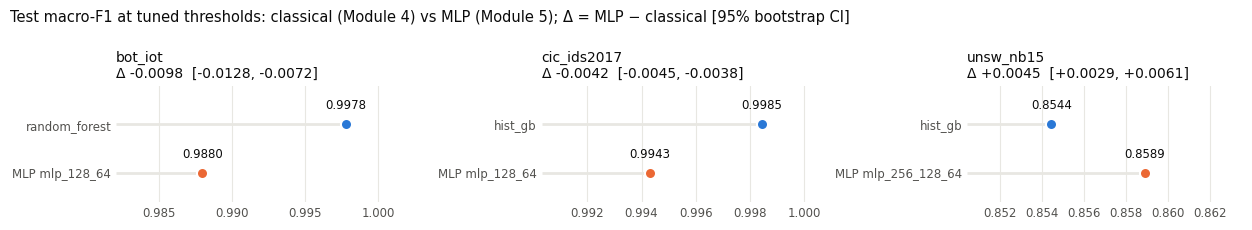

# Module 5 — MLP experiments

PyTorch MLPs on GPU Tesla T4; 3 experiments × 3 seeds per dataset, early stopping on validation macro-F1 (patience 6), class-balanced BCE. Final model retrained on train + val for its best epoch count.

## Validation macro-F1 (mean ± std over seeds)

| Experiment | bot_iot | cic_ids2017 | unsw_nb15 |
|---|---|---|---|
| mlp_128_64 | 0.9688 ± 0.0085 | 0.9961 ± 0.0001 | 0.9157 ± 0.0019 |
| mlp_256_128_64 | 0.9644 ± 0.0044 | 0.9959 ± 0.0000 | 0.9193 ± 0.0016 |
| mlp_512_256 | 0.9588 ± 0.0045 | 0.9955 ± 0.0002 | 0.9177 ± 0.0012 |

## Test: MLP vs classical (tuned thresholds)

| Dataset | Classical | MLP | Classical F1 | MLP F1 | Δ F1 [95% CI] | MLP FPR | Classical FPR | McNemar p |
|---|---|---|---|---|---|---|---|---|
| bot_iot | random_forest | mlp_128_64 | 0.9978 | 0.9880 | -0.0098 [-0.0128, -0.0072] | 0.0146 | 0.0015 | 3.47e-11 |
| cic_ids2017 | hist_gb | mlp_128_64 | 0.9985 | 0.9943 | -0.0042 [-0.0045, -0.0038] | 0.0023 | 0.0005 | 1.63e-121 |
| unsw_nb15 

In [ ]:
m4_sel = json.loads((M4_RES / "model_selection.json").read_text())
m4_test = pd.read_csv(M4_RES / "test_metrics.csv"); m4_val = pd.read_csv(M4_RES / "validation_metrics.csv")
CMP = []
for k in DATASETS:
    a = pd.read_parquet(M4_RES / "test_predictions" / f"{k}.parquet"); b = pd.read_parquet(RES / "test_predictions" / f"{k}.parquet")
    assert (a.row.values == b.row.values).all(), "test rows differ between Module 4 and Module 5"
    y = a.y_binary.values
    pa = (a.prob_attack.values >= m4_sel[k]["tuned_threshold"]).astype(int)
    pb = (b.prob_attack.values >= SELECTED[k]["tuned_threshold"]).astype(int)
    b_, c_, pval = mcnemar(y, pa, pb)
    diff, lo, hi = bootstrap_f1_diff(y, pa, pb)
    ra = m4_test[(m4_test.dataset == k) & (m4_test.threshold_rule == "tuned_on_val")].iloc[0]
    rb = test_tab[(test_tab.dataset == k) & (test_tab.threshold_rule == "tuned_on_val")].iloc[0]
    sk = m4_val[(m4_val.dataset == k) & (m4_val.model == "mlp")].iloc[0]
    CMP.append({"dataset": k, "classical_model": m4_sel[k]["model"], "mlp_experiment": SELECTED[k]["experiment"],
                "classical_test_f1_macro": ra.f1_macro, "mlp_test_f1_macro": rb.f1_macro, "f1_diff_mlp_minus_classical": diff,
                "diff_ci95_low": lo, "diff_ci95_high": hi, "classical_pr_auc": ra.pr_auc, "mlp_pr_auc": rb.pr_auc,
                "classical_fpr": ra.fpr, "mlp_fpr": rb.fpr, "classical_fnr": ra.fnr, "mlp_fnr": rb.fnr,
                "mcnemar_only_classical_right": b_, "mcnemar_only_mlp_right": c_, "mcnemar_p": pval,
                "sklearn_mlp_val_f1_macro": sk.f1_macro, "torch_mlp_val_f1_macro": SELECTED[k]["val_f1_macro_mean"]})
cmp = pd.DataFrame(CMP); cmp.to_csv(RES / "comparison_with_classical.csv", index=False)
display(cmp.round(5).T)

C_CL, C_MLP = SERIES[0], SERIES[1]
fig, axes = plt.subplots(1, len(cmp), figsize=(4.2 * len(cmp), 2.3))
for ax, (_, r) in zip(np.atleast_1d(axes), cmp.iterrows()):
    vals = [r.classical_test_f1_macro, r.mlp_test_f1_macro]; labels = [f"{r.classical_model}", f"MLP {r.mlp_experiment}"]
    lo = min(vals) - max(0.004, 0.6 * abs(vals[0] - vals[1])); hi = min(1.0, max(vals) + max(0.004, 0.6 * abs(vals[0] - vals[1])))
    for i, (v, c) in enumerate(zip(vals, [C_CL, C_MLP])):
        ax.hlines(i, lo, v, color=GRID, linewidth=2, zorder=1)
        ax.scatter(v, i, s=64, color=c, edgecolor="white", linewidth=1.5, zorder=3)
        ax.text(v, i - 0.32, f"{v:.4f}", ha="center", fontsize=8.5, color=INK)
    ax.set_xlim(lo, hi + (hi - lo) * 0.05); ax.set_ylim(1.6, -0.8)
    ax.set_yticks([0, 1]); ax.set_yticklabels(labels, color=INK)
    ax.set_title(f"{r.dataset}\nΔ {r.f1_diff_mlp_minus_classical:+.4f}  [{r.diff_ci95_low:+.4f}, {r.diff_ci95_high:+.4f}]",
                 loc="left", fontsize=10, color=INK)
    ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True); ax.tick_params(colors=MUTED, labelsize=8.5, length=0)
    for sp in ax.spines.values(): sp.set_visible(False)
fig.suptitle("Test macro-F1 at tuned thresholds: classical (Module 4) vs MLP (Module 5); Δ = MLP − classical [95% bootstrap CI]",
             x=0.01, ha="left", fontsize=10.5, color=INK)
fig.tight_layout(); fig.savefig(RES / "figures" / "mlp_vs_classical_test.png", dpi=200, bbox_inches="tight"); plt.show()

lines = ["# Module 5 — MLP experiments", "",
         f"PyTorch MLPs on {'GPU ' + GPU['name'] if GPU else 'CPU'}; {len(EXPERIMENTS)} experiments × {len(SEEDS)} seeds per dataset, "
         f"early stopping on validation macro-F1 (patience {PATIENCE}), class-balanced BCE. Final model retrained on train + val for its best epoch count.", "",
         "## Validation macro-F1 (mean ± std over seeds)", "", "| Experiment | " + " | ".join(DATASETS) + " |", "|---|" + "---|" * len(DATASETS)]
for name in EXPERIMENTS:
    cells = []
    for k in DATASETS:
        r = agg[(agg.dataset == k) & (agg.experiment == name)].iloc[0]
        cells.append(f"{r.f1_macro_mean:.4f} ± {0 if pd.isna(r.f1_macro_std) else r.f1_macro_std:.4f}")
    lines.append(f"| {name} | " + " | ".join(cells) + " |")
lines += ["", "## Test: MLP vs classical (tuned thresholds)", "",
          "| Dataset | Classical | MLP | Classical F1 | MLP F1 | Δ F1 [95% CI] | MLP FPR | Classical FPR | McNemar p |", "|---|---|---|---|---|---|---|---|---|"]
for _, r in cmp.iterrows():
    lines.append(f"| {r.dataset} | {r.classical_model} | {r.mlp_experiment} | {r.classical_test_f1_macro:.4f} | {r.mlp_test_f1_macro:.4f} | "
                 f"{r.f1_diff_mlp_minus_classical:+.4f} [{r.diff_ci95_low:+.4f}, {r.diff_ci95_high:+.4f}] | {r.mlp_fpr:.4f} | {r.classical_fpr:.4f} | {r.mcnemar_p:.3g} |")
(RES / "summary.md").write_text("\n".join(lines))
manifest = {"created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"), "module": "5 - MLP experiments",
            "device": GPU or "cpu", "torch": torch.__version__, "selection": SELECTED,
            "final_models": {k: {**{kk: vv for kk, vv in v.items() if kk != "path"}, "path": str(v["path"].relative_to(BASE)),
                                 "sha256": sha256_file(v["path"])} for k, v in FINAL.items()}}
(RES / "module5_manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
print("\n".join(lines))